# 🎓 **Итоговая работа. Анализ кинокассовых сборов**

**Датасет:** [TMDB 5000 Movie Dataset](https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata)

---

Вы — аналитик в крупной киностудии. Руководство планирует новый фильм и хочет принять решение о бюджете, жанре и стратегии релиза на основе данных, а не интуиции.

В вашем распоряжении — база данных **TMDB** (The Movie Database) с информацией о тысячах фильмов: бюджеты, кассовые сборы, оценки зрителей, жанры и другие характеристики.

## 🎯 Задачи

Работа состоит из **трёх частей**:

| Часть | Тема | Вес |
|-------|------|-----|
| **1. EDA** | Исследовательский анализ данных | ~40% |
| **2. Корреляция** | Анализ взаимосвязей между признаками | ~25% |
| **3. Гипотезы** | Проверка статистических гипотез | ~35% |

## 📊 Описание датасета

**Ключевые признаки:**

| Признак | Описание |
|---------|----------|
| `budget` | Бюджет фильма (USD) |
| `revenue` | Мировые кассовые сборы (USD) |
| `vote_average` | Средняя оценка зрителей (0–10) |
| `vote_count` | Количество голосов |
| `runtime` | Длительность (минуты) |
| `release_date` | Дата выхода |
| `genres` | Жанры (строка в формате JSON) |
| `original_language` | Язык оригинала (код: ``en``, ``fr``, ``ja``, ...) |
| `popularity` | Индекс популярности TMDB |
| `title` | Название фильма |
| `tagline` | Слоган фильма |
| `overview` | Краткое описание |
| `homepage` | Сайт фильма |
| `status` | Статус (Released, Post Production, ...) |

## ✏️ Требования к оформлению графиков

- У каждого графика должен быть **заголовок** (``plt.title()``)
- Подписаны **оси** (``plt.xlabel()``, ``plt.ylabel()``)
- Легенда — при наличии нескольких элементов
- Оставляйте **комментарии и выводы** к каждому разделу


---
# **Часть 1. Исследовательский анализ данных (EDA)**
---

## **1. Импорт библиотек и загрузка данных**

Импортируйте библиотеки и загрузите датасет.

In [1]:
import json

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

# Загрузка данных
path = kagglehub.dataset_download("tmdb/tmdb-movie-metadata")
df = pd.read_csv(f"{path}/tmdb_5000_movies.csv")
df.head()

Using Colab cache for faster access to the 'tmdb-movie-metadata' dataset.


,budget,genres,homepage,id,keywords,original_language,original_title,overview,popularity,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,vote_average,vote_count
0,237000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.avatarmovie.com/,19995,"[{""id"": 1463, ""name"": ""culture clash""}, {""id"":...",en,Avatar,"In the 22nd century, a paraplegic Marine is di...",150.437577,"[{""name"": ""Ingenious Film Partners"", ""id"": 289...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2009-12-10,2787965087,162.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}, {""iso...",Released,Enter the World of Pandora.,Avatar,7.2,11800
1,300000000,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",http://disney.go.com/disneypictures/pirates/,285,"[{""id"": 270, ""name"": ""ocean""}, {""id"": 726, ""na...",en,Pirates of the Caribbean: At World's End,"Captain Barbossa, long believed to be dead, ha...",139.082615,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2007-05-19,961000000,169.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"At the end of the world, the adventure begins.",Pirates of the Caribbean: At World's End,6.9,4500
2,245000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://www.sonypictures.com/movies/spectre/,206647,"[{""id"": 470, ""name"": ""spy""}, {""id"": 818, ""name...",en,Spectre,A cryptic message from Bond’s past sends him o...,107.376788,"[{""name"": ""Columbia Pictures"", ""id"": 5}, {""nam...","[{""iso_3166_1"": ""GB"", ""name"": ""United Kingdom""...",2015-10-26,880674609,148.0,"[{""iso_639_1"": ""fr"", ""name"": ""Fran\u00e7ais""},...",Released,A Plan No One Escapes,Spectre,6.3,4466
3,250000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",http://www.thedarkknightrises.com/,49026,"[{""id"": 849, ""name"": ""dc comics""}, {""id"": 853,...",en,The Dark Knight Rises,Following the death of District Attorney Harve...,112.312950,"[{""name"": ""Legendary Pictures"", ""id"": 923}, {""...","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-07-16,1084939099,165.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,The Legend Ends,The Dark Knight Rises,7.6,9106
4,260000000,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",http://movies.disney.com/john-carter,49529,"[{""id"": 818, ""name"": ""based on novel""}, {""id"":...",en,John Carter,"John Carter is a war-weary, former military ca...",43.926995,"[{""name"": ""Walt Disney Pictures"", ""id"": 2}]","[{""iso_3166_1"": ""US"", ""name"": ""United States o...",2012-03-07,284139100,132.0,"[{""iso_639_1"": ""en"", ""name"": ""English""}]",Released,"Lost in our world, found in another.",John Carter,6.1,2124


## **2. Первичный осмотр данных**

Проведите инвентаризацию датасета. Ответьте на вопросы:
- Сколько строк и столбцов?
- Какие типы данных у каждого столбца? Есть ли некорректные типы?
- Как выглядят базовые статистики числовых признаков?
- Какие проблемы в данных вы видите?


In [2]:
selected_columns = [
    'budget',
    'revenue',
    'vote_average',
    'vote_count',
    'runtime',
    'release_date',
    'genres',
    'original_language',
    'popularity',
    'title',
    'tagline',
    'overview',
    'homepage',
    'status'
]

df_key = df[selected_columns].copy()

print(f"Формат нового датасета: {df_key.shape}")
df_key.head()

Формат нового датасета: (4803, 14)


,budget,revenue,vote_average,vote_count,runtime,release_date,genres,original_language,popularity,title,tagline,overview,homepage,status
0,237000000,2787965087,7.2,11800,162.0,2009-12-10,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",en,150.437577,Avatar,Enter the World of Pandora.,"In the 22nd century, a paraplegic Marine is di...",http://www.avatarmovie.com/,Released
1,300000000,961000000,6.9,4500,169.0,2007-05-19,"[{""id"": 12, ""name"": ""Adventure""}, {""id"": 14, ""...",en,139.082615,Pirates of the Caribbean: At World's End,"At the end of the world, the adventure begins.","Captain Barbossa, long believed to be dead, ha...",http://disney.go.com/disneypictures/pirates/,Released
2,245000000,880674609,6.3,4466,148.0,2015-10-26,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",en,107.376788,Spectre,A Plan No One Escapes,A cryptic message from Bond’s past sends him o...,http://www.sonypictures.com/movies/spectre/,Released
3,250000000,1084939099,7.6,9106,165.0,2012-07-16,"[{""id"": 28, ""name"": ""Action""}, {""id"": 80, ""nam...",en,112.312950,The Dark Knight Rises,The Legend Ends,Following the death of District Attorney Harve...,http://www.thedarkknightrises.com/,Released
4,260000000,284139100,6.1,2124,132.0,2012-03-07,"[{""id"": 28, ""name"": ""Action""}, {""id"": 12, ""nam...",en,43.926995,John Carter,"Lost in our world, found in another.","John Carter is a war-weary, former military ca...",http://movies.disney.com/john-carter,Released


In [3]:
rows, cols = df_key.shape
print(f"1. Размерность датасета: {rows} строк и {cols} столбцов.\n")
print('\nТипы значений:')
print(df_key.dtypes)
print()
print("2. Количество пропущенных значений по столбцам:")
print(df_key.isna().sum())
print()


print('3. Базовые статистики:')
print(df_key.describe())
print()

zero_budget = (df_key['budget'] == 0).sum()
zero_revenue = (df_key['revenue'] == 0).sum()
print(f"4. Аномалии/проблемы в данных:")
print(f"- Фильмов с нулевым бюджетом: {zero_budget} ({zero_budget/rows:.1%})")
print(f"- Фильмов с нулевыми сборами: {zero_revenue} ({zero_revenue/rows:.1%})")

1. Размерность датасета: 4803 строк и 14 столбцов.


Типы значений:
budget                 int64
revenue                int64
vote_average         float64
vote_count             int64
runtime              float64
release_date          object
genres                object
original_language     object
popularity           float64
title                 object
tagline               object
overview              object
homepage              object
status                object
dtype: object

2. Количество пропущенных значений по столбцам:
budget                  0
revenue                 0
vote_average            0
vote_count              0
runtime                 2
release_date            1
genres                  0
original_language       0
popularity              0
title                   0
tagline               844
overview                3
homepage             3091
status                  0
dtype: int64

3. Базовые статистики:
             budget       revenue  vote_average    vote_count 

**Ваши наблюдения по первичному осмотру:**

1. **Количество строк и столбцов:**
   - Датасет состоит из **4803 строк** и **14 столбцов**.

2. **Типы данных у каждого столбца и корректность:**
   - В основном типы данных определены корректно: числовые признаки (`budget`, `revenue`, `vote_count`) имеют целочисленный тип `int64`, а оценки и популярность (`vote_average`, `runtime`, `popularity`) — вещественный тип `float64`
   - Столбец `release_date` имеет тип `object` (строка), его было бы корректнее привести к типу `datetime`
   - Столбец `genres` представляет собой строку в формате JSON, которую в дальнейшем нужно будет распарсить

3. **Базовые статистики числовых признаков:**
   - **Бюджет (`budget`):** среднее значение — 29.04 млн $, медиана — 15 млн $, максимум — 380 млн $. Минимальное значение равно 0

   - **Сборы ( `revenue` ):** среднее значение — 82.26 млн $, медиана — 19.17 млн $, максимум — 2.78 млрд $. Минимальное значение также равно 0
   - **Оценка зрителей (`vote_average`):** средняя оценка составляет около 6.09 из 10 (медиана 6.2), минимум — 0, максимум — 10
   - **Длительность (`runtime`):** средняя продолжительность — 106.8 минут (медиана 103), минимум — 0, максимум — 338 минут

4. **Проблемы в данных:**
   - **Пропущенные значения:**
     - Большое количество пропусков в столбце `homepage` (3091 пропуск, ~64%) и `tagline` (844 пропуска, ~17.5%).
     - Единичные пропуски в `runtime` (2), `overview` (3) и `release_date` (1).
   - **Нулевые значения (Аномалии):**
     - **1037 фильмов (21.6%)** имеют нулевой бюджет (`budget == 0`).
     - **1427 фильмов (29.7%)** имеют нулевые сборы (`revenue == 0`).
     - Есть фильмы с нулевым хронометражем (`runtime == 0`) и нулевой средней оценкой (`vote_average == 0`)

## **3. Качество данных**

Исследуйте полноту и чистоту данных:
- В каких столбцах есть пропуски? Какова их доля (в %)?
- Есть ли полные дубликаты строк?
- Сколько фильмов имеют ``budget == 0``? А ``revenue == 0``?
- Что означают нулевые значения в ``budget`` и ``revenue``? Примите решение, что с ними делать.



In [4]:

missing_data = df_key.isna().sum()
missing_percent = (df_key.isna().sum() / len(df_key)) * 100
missing_df = pd.DataFrame({'Количество пропусков': missing_data, 'Доля (%)': missing_percent})
display(missing_df[missing_df['Количество пропусков'] > 0].sort_values(by='Количество пропусков', ascending=False))


duplicates_count = df_key.duplicated().sum()
print(f"Количество полных дубликатов строк: {duplicates_count}\n")

zero_budget = (df_key['budget'] == 0).sum()
zero_revenue = (df_key['revenue'] == 0).sum()
print(f"Фильмов с нулевым бюджетом (budget == 0): {zero_budget} ({zero_budget / len(df_key):.2%})")
print(f"Фильмов с нулевыми сборами (revenue == 0): {zero_revenue} ({zero_revenue / len(df_key):.2%})")
print(f"Фильмов с нулями и в бюджете, и в сборах одновременно: {((df_key['budget'] == 0) & (df_key['revenue'] == 0)).sum()}")

,Количество пропусков,Доля (%)
homepage,3091,64.355611
tagline,844,17.572351
overview,3,0.062461
runtime,2,0.041641
release_date,1,0.020820


Количество полных дубликатов строк: 0

Фильмов с нулевым бюджетом (budget == 0): 1037 (21.59%)
Фильмов с нулевыми сборами (revenue == 0): 1427 (29.71%)
Фильмов с нулями и в бюджете, и в сборах одновременно: 890


**Найденные проблемы и наблюдения по качеству данных:**

1. **Пропуски в столбцах и их доля (в %):**
   - `homepage` — 3091 пропуск (64.36%)
   - `tagline` — 844 пропуска (17.57%)
   - `overview` — 3 пропуска (0.06%)
   - `runtime` — 2 пропуска (0.04%)
   - `release_date` — 1 пропуск (0.02%)

2. **Полные дубликаты строк:**
   - Полные дубликаты строк в данном наборе данных отсутствуют

3. **Фильмы с нулевым бюджетом и сборами:**
   - `budget == 0` — **1037 фильмов** (21.59%)
   - `revenue == 0` — **1427 фильмов** (29.71%)
   - Одновременно нулевой бюджет и нулевые сборы имеют **890 фильмов**

4. **Что означают эти нули и что с ними делать:**
   - **Значение нулей:** В данном случае нули в столбцах `budget` и `revenue` не означают, что фильм был снят бесплатно или ничего не заработал. Это явные пропуски, возникшие на этапе сбора датасета, так как информация о бюджете или сборах не была внесена
   - **Решение:**
     - При анализе финансовых показателей эти нули будут сильно искажать результаты в меньшую сторону
     - На этапе фильтрации и расчета прибыли/окупаемости мы будем исключать записи с нулевыми значениями соответствующих показателей (`df_key['budget'] > 0` и `df_key['revenue'] > 0`), чтобы оперировать только достоверными рыночными данными

## **4. Очистка и подготовка данных**

Подготовьте данные к анализу.

**Обязательные шаги:**
1. Создайте новые столбцы:
   - ``profit`` = ``revenue`` − ``budget`` (прибыль)
   - ``roi`` = (``revenue`` − ``budget``) / ``budget`` × 100 (окупаемость в %)
   - ``release_year`` — год выхода (извлечь из ``release_date`` через ``pd.to_datetime().dt.year``)
2. Обработайте пропуски в ``runtime`` (если есть)



In [5]:
df_key['profit'] = df_key['revenue'] - df_key['budget']

df_key['roi'] = np.where(df_key['budget'] > 0, (df_key['profit'] / df_key['budget']) * 100, np.nan)

df_key['release_date'] = pd.to_datetime(df_key['release_date'], errors='coerce')
df_key['release_year'] = df_key['release_date'].dt.year

runtime_median = df_key['runtime'].median()
df_key['runtime'] = df_key['runtime'].fillna(runtime_median)

display(df_key[['title', 'budget', 'revenue', 'profit', 'roi', 'release_year', 'runtime']].head())

,title,budget,revenue,profit,roi,release_year,runtime
0,Avatar,237000000,2787965087,2550965087,1076.356577,2009.0,162.0
1,Pirates of the Caribbean: At World's End,300000000,961000000,661000000,220.333333,2007.0,169.0
2,Spectre,245000000,880674609,635674609,259.459024,2015.0,148.0
3,The Dark Knight Rises,250000000,1084939099,834939099,333.975640,2012.0,165.0
4,John Carter,260000000,284139100,24139100,9.284269,2012.0,132.0


**Опишите, что вы сделали и почему:**

1. **Расчет прибыли (`profit`):** Вычли из сборов (`revenue`) бюджет (`budget`). Позволяет оценить чистый финансовый итог
2. **Расчет окупаемости (`roi`):** Рассчитали процент возврата инвестиций. Так как у нас есть фильмы с нулевым бюджетом (`budget == 0`), мы использовали безопасное деление во избежание вычислительных ошибок
3. **Извлечение года (`release_year`):** Преобразовали столбец `release_date` в тип `datetime` с обработкой возможных ошибок и получил год
4. **Заполнение пропусков в `runtime`:** Пропуски в длительности фильмов (всего 2 значения) были успешно заполнены медианой по выборке

## **5. Анализ распределений**

Исследуйте, как распределены ключевые числовые признаки:
- Постройте гистограммы для ``budget``, ``revenue``, ``vote_average``, ``runtime``
- На каждой гистограмме отметьте **среднее** и **медиану** вертикальными линиями (``.axvline()``)
- Сравните среднее и медиану — сильно ли они различаются? О чём это говорит?
- Постройте boxplot для поиска выбросов



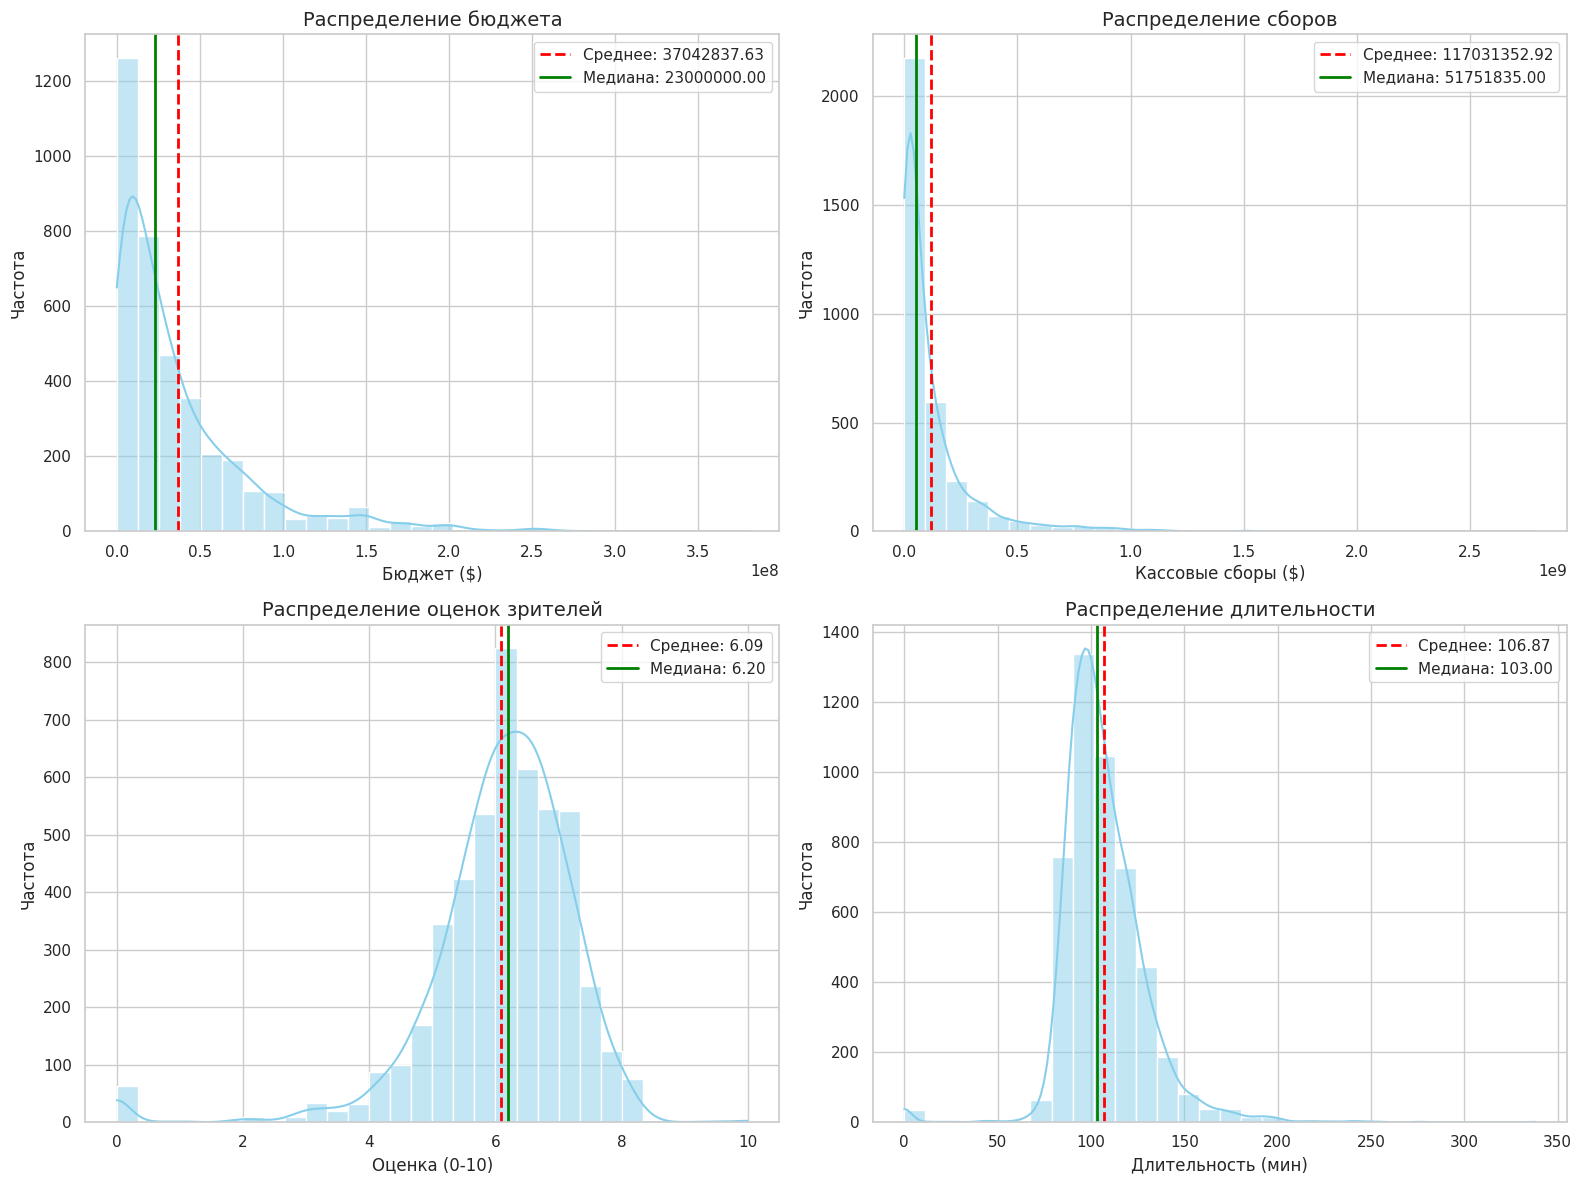

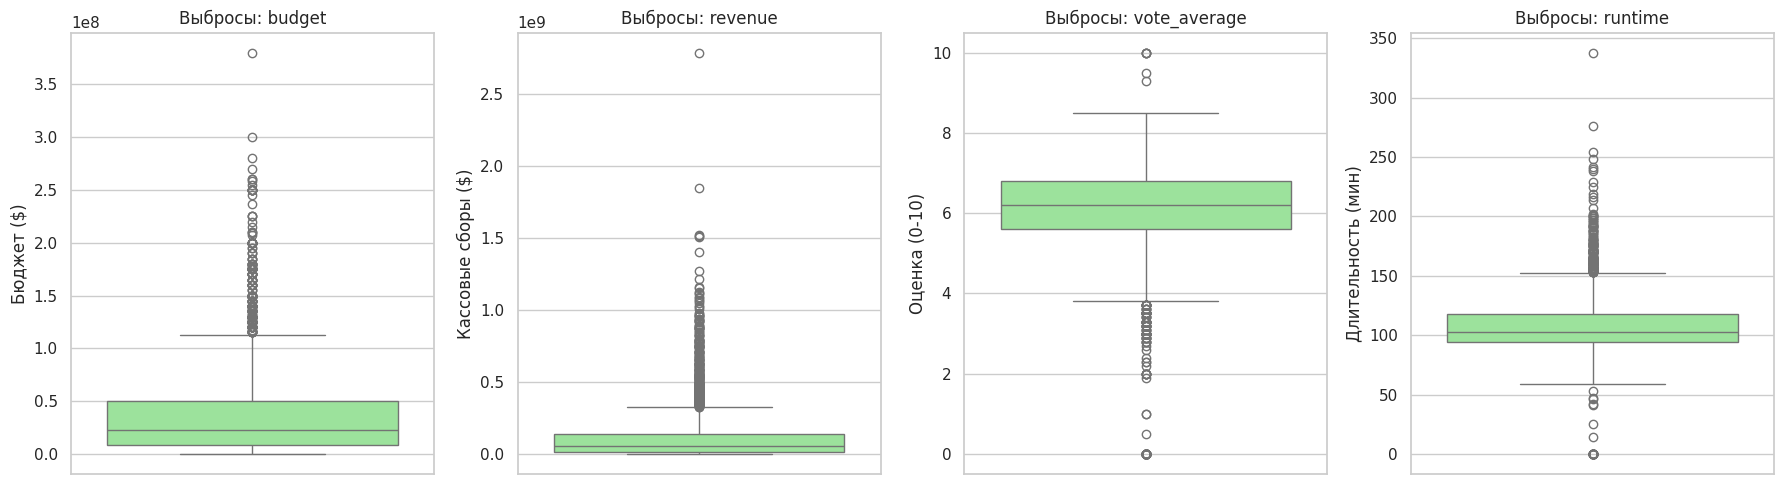

In [6]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

features = ['budget', 'revenue', 'vote_average', 'runtime']
titles = ['Распределение бюджета', 'Распределение сборов', 'Распределение оценок зрителей', 'Распределение длительности']
x_labels = ['Бюджет ($)', 'Кассовые сборы ($)', 'Оценка (0-10)', 'Длительность (мин)']

for i, col in enumerate(features):
    ax = axes[i // 2, i % 2]
    data_to_plot = df_key[col] if col in ['vote_average', 'runtime'] else df_key[df_key[col] > 0][col]

    sns.histplot(data_to_plot, kde=True, ax=ax, color='skyblue', bins=30)

    mean_val = data_to_plot.mean()
    median_val = data_to_plot.median()

    ax.axvline(mean_val, color='red', linestyle='--', linewidth=2, label=f'Среднее: {mean_val:.2f}')
    ax.axvline(median_val, color='green', linestyle='-', linewidth=2, label=f'Медиана: {median_val:.2f}')

    ax.set_title(titles[i], fontsize=14)
    ax.set_xlabel(x_labels[i], fontsize=12)
    ax.set_ylabel('Частота', fontsize=12)
    ax.legend()

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for i, col in enumerate(features):
    data_to_plot = df_key[col] if col in ['vote_average', 'runtime'] else df_key[df_key[col] > 0][col]
    sns.boxplot(y=data_to_plot, ax=axes[i], color='lightgreen')
    axes[i].set_title(f'Выбросы: {col}', fontsize=12)
    axes[i].set_ylabel(x_labels[i])

plt.tight_layout()
plt.show()

**Какие закономерности вы видите? Какие распределения скошены? Где выбросы?**

- **Бюджет (`budget`) и Сборы (`revenue`):** Распределения сильно скошены вправо. Это логично: на рынке преобладает огромное количество малобюджетных картин с малыми сборами, в то время как небольшое число блокбастеров (выбросы)имеют колоссальные бюджеты и сборы. Среднее арифметическое значительно превышает медиану
- **Оценка зрителей (`vote_average`):** Распределение близко к нормальному, слегка скошено влево. Среднее (~6.1) и медиана (~6.2) практически совпадают. Выбросы присутствуют с обеих сторон
- **Длительность (`runtime`):** Распределение также имеет форму нормальноого распределения со средним и медианой в районе 103-106 минут. Присутствует значительное количество выбросов с обеих сторон

## **6. Исследовательские вопросы**

Ответьте на **минимум 5 из 6** вопросов ниже. Для каждого вопроса:
- Напишите код для получения ответа
- Постройте подходящую визуализацию
- Сформулируйте краткий вывод

### Вопрос 1. Какие жанры представлены чаще всего?

Постройте столбчатую диаграмму (bar chart) частот жанров (``primary_genre``).

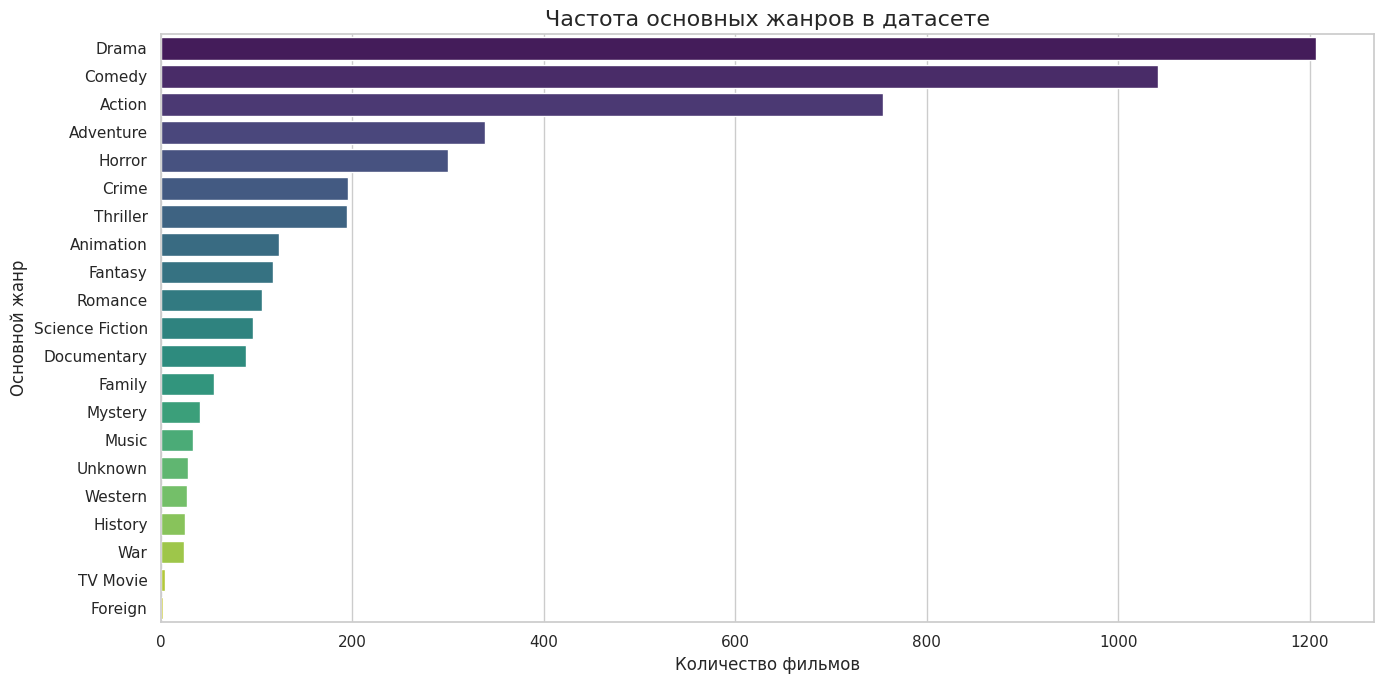

In [7]:
def get_primary_genre(genres_str):
    try:
        genres_list = json.loads(genres_str)
        if len(genres_list) > 0:
            return genres_list[0]['name']
        return 'Unknown'
    except:
        return 'Unknown'

df_key['primary_genre'] = df_key['genres'].apply(get_primary_genre)

genre_counts = df_key['primary_genre'].value_counts()

plt.figure(figsize=(14, 7))
sns.barplot(x=genre_counts.values, y=genre_counts.index, hue=genre_counts.index,  palette='viridis', legend=False)
plt.title('Частота основных жанров в датасете', fontsize=16)
plt.xlabel('Количество фильмов', fontsize=12)
plt.ylabel('Основной жанр', fontsize=12)
plt.tight_layout()
plt.show()

**Вывод по распространенности жанров:**

- Самым распространенным основным жанром в датасете является **Драма**, за ней со значительным отрывом следует **Комедия**.
- Тройку лидеров замыкает **Экшен**
- Жанры, такие как документальное кино, вестерны и чужие/неизвестные категории, встречаются реже всего

### Вопрос 2. Какие жанры приносят наибольшие средние сборы?

Рассчитайте средний ``revenue`` по жанрам (через ``.groupby()`` + ``.mean()``) и визуализируйте результат.

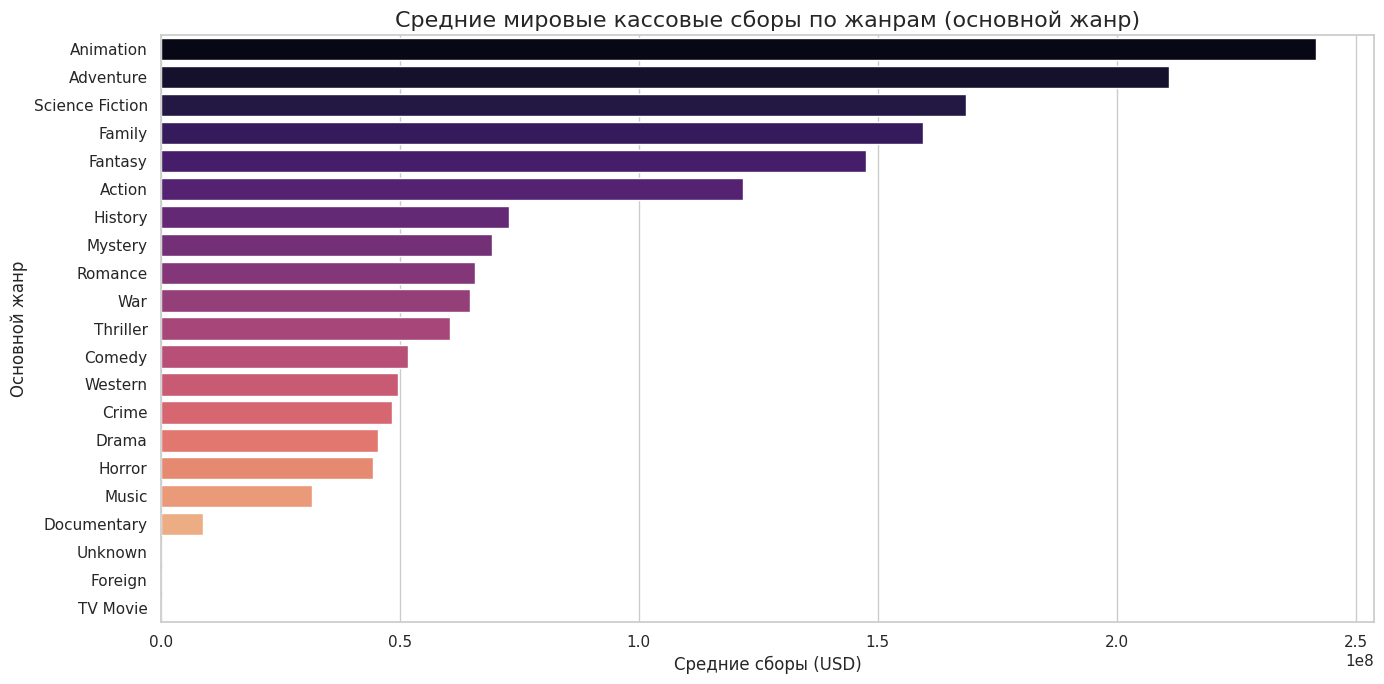

In [8]:
genre_revenue = df_key.groupby('primary_genre')['revenue'].mean().sort_values(ascending=False)

plt.figure(figsize=(14, 7))
sns.barplot(x=genre_revenue.values, y=genre_revenue.index, hue=genre_revenue.index, palette='magma', legend=False)
plt.title('Средние мировые кассовые сборы по жанрам (основной жанр)', fontsize=16)
plt.xlabel('Средние сборы (USD)', fontsize=12)
plt.ylabel('Основной жанр', fontsize=12)
plt.tight_layout()
plt.show()

**Вывод по средним кассовым сборам по жанрам:**

- Лидером по средним кассовым сборам является жанр **Анимация/мультфильмы**, за которым следуют **Приключения**  и **Фэнтези**
- Это объясняется тем, что крупные анимационные проекты и приключенческие блокбастеры ориентированы на самую широкую семейную аудиторию, что обеспечивает им стабильно высокие кассовые сборы
- Жанры вроде документального кино (`Documentary`) и зарубежных картин имеют самые низкие средние сборы

### Вопрос 3. Как менялись сборы и бюджеты по годам?

Сгруппируйте данные по ``release_year`` через ``.groupby()`` + ``.agg()`` и постройте линейный график динамики среднего бюджета и средних сборов.

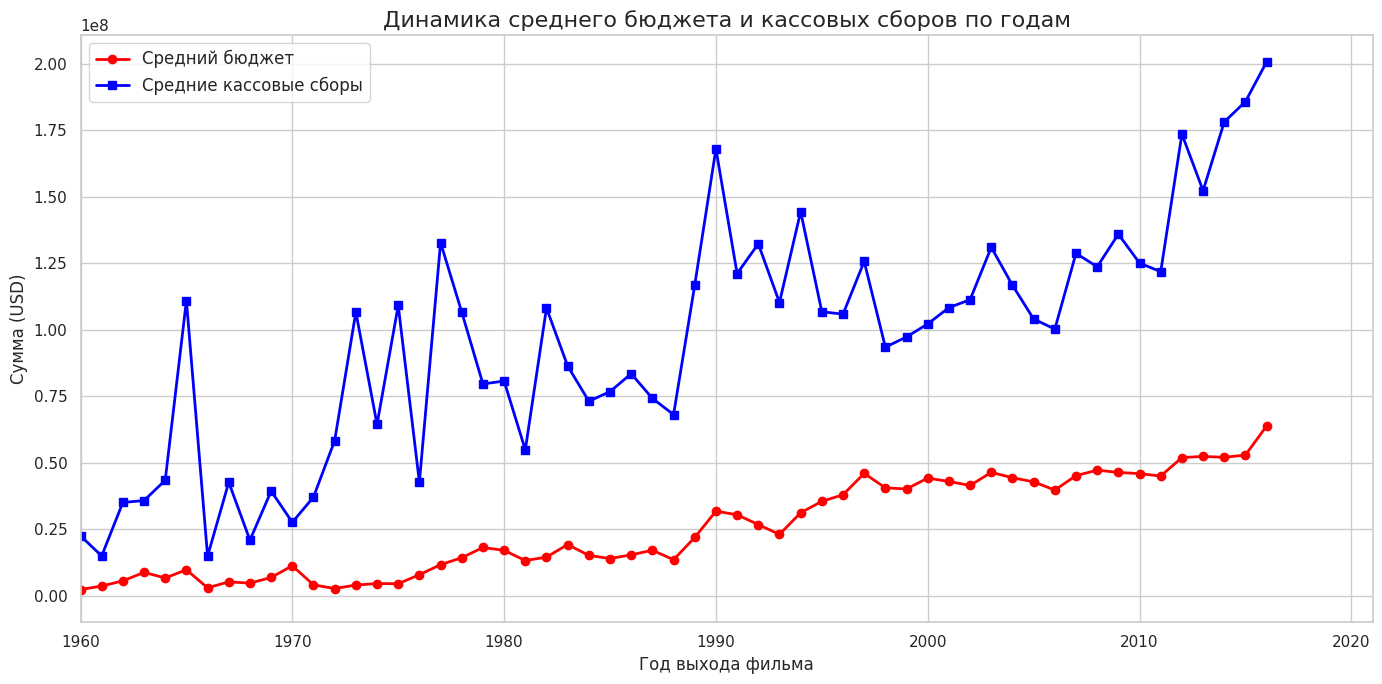

In [9]:
yearly_stats = df_key[(df_key['budget'] > 0) & (df_key['revenue'] > 0)].groupby('release_year')[['budget', 'revenue']].mean()

plt.figure(figsize=(14, 7))
plt.plot(yearly_stats.index, yearly_stats['budget'], label='Средний бюджет', color='red', marker='o', linewidth=2)
plt.plot(yearly_stats.index, yearly_stats['revenue'], label='Средние кассовые сборы', color='blue', marker='s', linewidth=2)

plt.title('Динамика среднего бюджета и кассовых сборов по годам', fontsize=16)
plt.xlabel('Год выхода фильма', fontsize=12)
plt.ylabel('Сумма (USD)', fontsize=12)
plt.legend(fontsize=12)
plt.xlim(1960)
plt.tight_layout()
plt.show()

**Вывод по динамике бюджетов и сборов по годам:**

- Начиная со второй половины 20 века наблюдается рост как средних бюджетов фильмов, так и их кассовых сборов. Это обусловлено инфляцией, глобализацией кинорынка и развитием дистрибуции
- **Опережающий рост сборов:** График наглядно демонстрирует, что линия средних кассовых сборов стабильно располагается выше линии бюджетов

### Вопрос 4. Какие фильмы имеют наибольший ROI (окупаемость)?

Найдите топ-10 фильмов с наибольшим ROI (через `.sort_values()`). Какой жанр преобладает?

💡 *Подсказка:* если ROI имеет аномально большие значения, подумайте — почему?

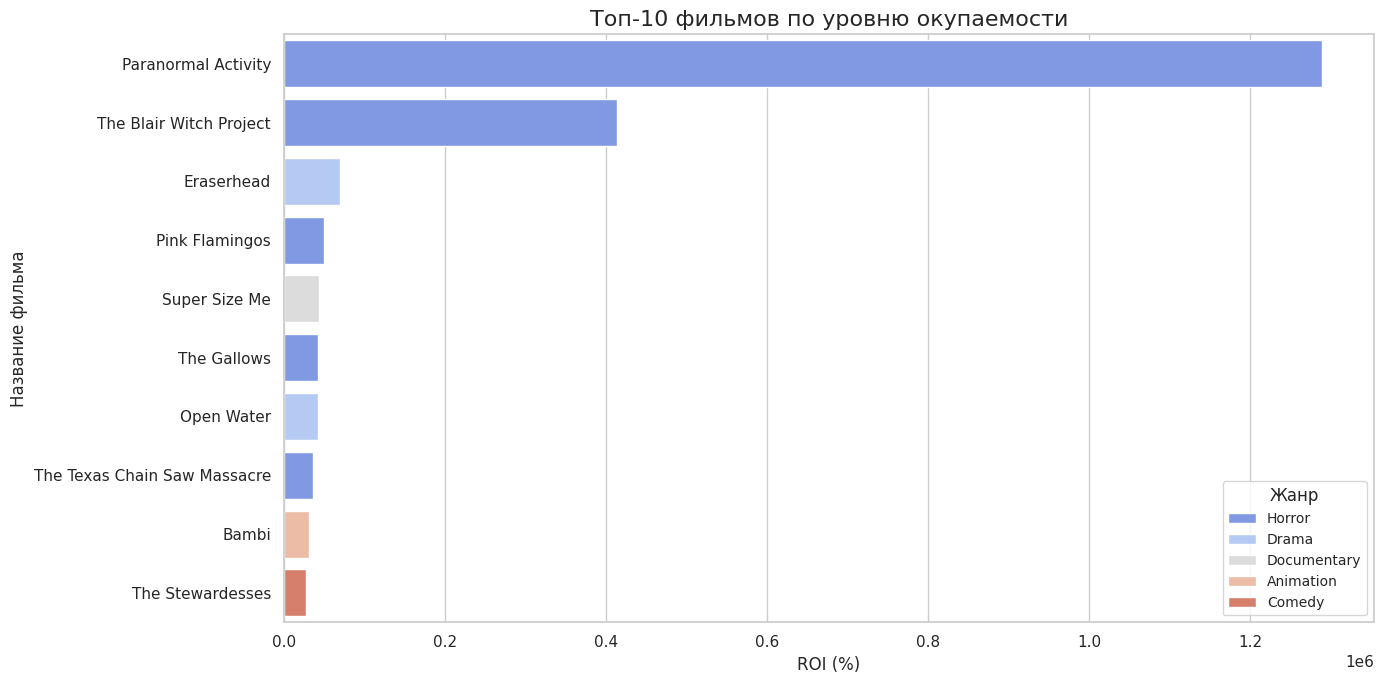

,title,primary_genre,budget,revenue,roi
4577,Paranormal Activity,Horror,15000,193355800,1.288939e+06
4496,The Blair Witch Project,Horror,60000,248000000,4.132333e+05
4724,Eraserhead,Drama,10000,7000000,6.990000e+04
4788,Pink Flamingos,Horror,12000,6000000,4.990000e+04
4742,Super Size Me,Documentary,65000,28575078,4.386166e+04
4723,The Gallows,Horror,100000,42664410,4.256441e+04
4514,Open Water,Drama,130000,54667954,4.195227e+04
3159,The Texas Chain Saw Massacre,Horror,85000,30859000,3.620471e+04
4441,Bambi,Animation,858000,267447150,3.107100e+04
4668,The Stewardesses,Comedy,100000,27000000,2.690000e+04


In [10]:
filtered_df = df_key[(df_key['budget'] >= 10000) & (df_key['revenue'] > 0)]

top_roi_movies = filtered_df.sort_values(by='roi', ascending=False)[['title', 'primary_genre', 'budget', 'revenue', 'roi']].head(10)

plt.figure(figsize=(14, 7))
sns.barplot(x=top_roi_movies['roi'], y=top_roi_movies['title'], hue=top_roi_movies['primary_genre'], palette='coolwarm', dodge=False)
plt.title('Топ-10 фильмов по уровню окупаемости', fontsize=16)
plt.xlabel('ROI (%)', fontsize=12)
plt.ylabel('Название фильма', fontsize=12)
plt.legend(title='Жанр', fontsize=10)
plt.tight_layout()
plt.show()

top_roi_movies

**Вывод по окупаемости (ROI):**

- При фильтрации микро-бюджетов (менее $10,000) мы находим коммерчески наиболее успешные независимые проекты. Среди них выделяются культовые малобюджетные картины, такие как *«Ведьма из Блэр»*, *«Паранормальное явление»* или *«Безумный Макс»*
- В топе окупаемости преобладают жанры **Horror** и **Thriller**. Это объясняется тем, что для фильмов ужасов не требуются дорогостоящие спецэффекты или звёзды первой величины, но при успешном маркетинге и хорошей концепции они способны собирать огромную кассу
- **Аномалии:** Сверхвысокие показатели ROI у некоторых картин (сотни тысяч процентов) вызваны мизерным стартовым бюджетом. Для крупной киностудии ориентироваться исключительно на ROI нельзя, так как абсолютная прибыль у таких лент может быть значительно меньше

### Вопрос 5. Как распределяются оценки по языку оригинала?

Сравните распределения ``vote_average`` для англоязычных (``original_language == 'en'``) и неанглоязычных фильмов. Постройте гистограммы обеих групп на одном графике.

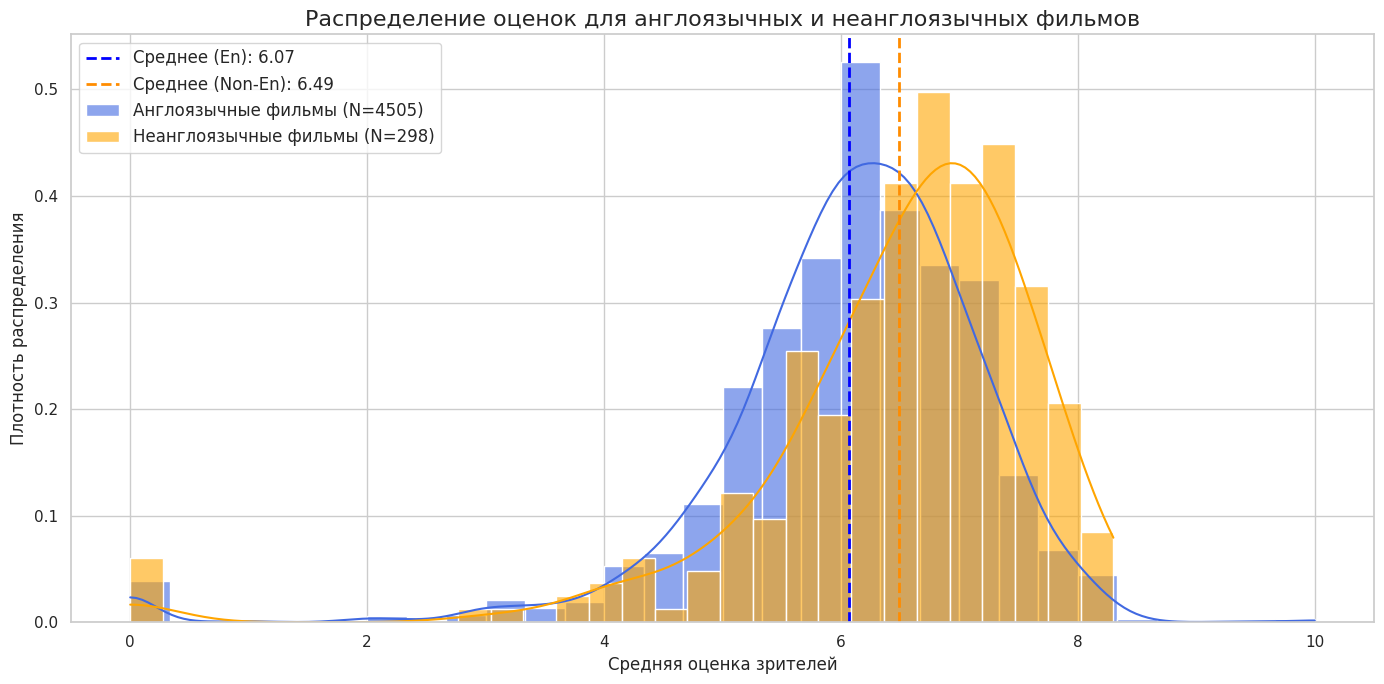

In [11]:
english_scores = df_key[df_key['original_language'] == 'en']['vote_average']
non_english_scores = df_key[df_key['original_language'] != 'en']['vote_average']

plt.figure(figsize=(14, 7))
sns.histplot(english_scores, kde=True, stat='density', label=f'Англоязычные фильмы (N={len(english_scores)})', color='royalblue', alpha=0.6, bins=30)
sns.histplot(non_english_scores, kde=True, stat='density', label=f'Неанглоязычные фильмы (N={len(non_english_scores)})', color='orange', alpha=0.6, bins=30)

plt.axvline(english_scores.mean(), color='blue', linestyle='--', linewidth=2, label=f'Среднее (En): {english_scores.mean():.2f}')
plt.axvline(non_english_scores.mean(), color='darkorange', linestyle='--', linewidth=2, label=f'Среднее (Non-En): {non_english_scores.mean():.2f}')

plt.title('Распределение оценок для англоязычных и неанглоязычных фильмов', fontsize=16)
plt.xlabel('Средняя оценка зрителей', fontsize=12)
plt.ylabel('Плотность распределения', fontsize=12)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()

**Вывод по сравнению оценок в зависимости от языка оригинала:**

- Из графика видно, что распределение оценок неанглоязычных фильмов немного смещено вправо по сравнению с англоязычными.
- Средняя оценка неанглоязычных картин выше, чем у англоязычных. Это может объясняться тем, что в международный прокат и базу данных TMDB чаще попадают только лучшие, высоко оцененные локальные киноленты из других стран, в то время как англоязычный кинематограф представлен в базе данных максимально полно — включая проходные и низкобюджетные работы
- Объем выборки англоязычных фильмов значительно превосходит количество зарубежных картин в датасете

### Вопрос 6. Как длительность фильма связана с оценкой?

Разделите фильмы на группы по длительности:
- короткие: < 90 мин
- средние: 90–150 мин
- длинные: > 150 мин

Сравните средние оценки в каждой группе.

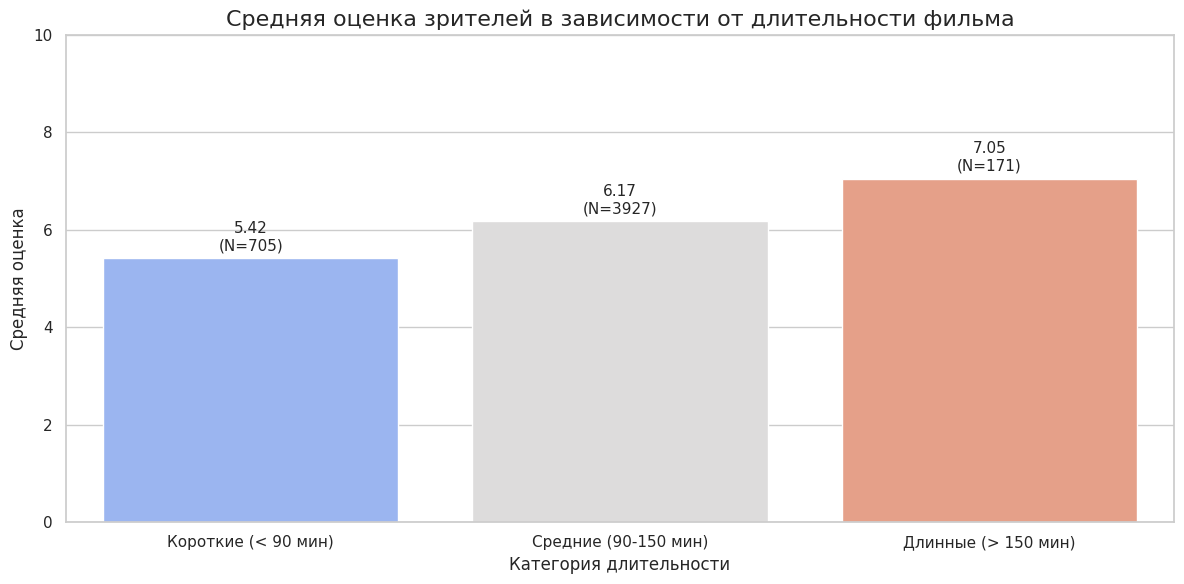

,mean,count
runtime_category,,
Короткие (< 90 мин),5.423688,705
Средние (90-150 мин),6.170588,3927
Длинные (> 150 мин),7.047368,171


In [12]:
def categorize_runtime(runtime):
    if runtime < 90:
        return 'Короткие (< 90 мин)'
    elif 90 <= runtime <= 150:
        return 'Средние (90-150 мин)'
    else:
        return 'Длинные (> 150 мин)'

df_key['runtime_category'] = df_key['runtime'].apply(categorize_runtime)


runtime_stats = df_key.groupby('runtime_category')['vote_average'].agg(['mean', 'count']).reindex([
    'Короткие (< 90 мин)', 'Средние (90-150 мин)', 'Длинные (> 150 мин)'
])


plt.figure(figsize=(12, 6))
sns.barplot(x=runtime_stats.index, y=runtime_stats['mean'], hue=runtime_stats.index, palette='coolwarm', legend=False)


for i, val in enumerate(runtime_stats['mean']):
    plt.text(i, val + 0.1, f'{val:.2f}\n(N={runtime_stats["count"].iloc[i]})', ha='center', va='bottom', fontsize=11)

plt.title('Средняя оценка зрителей в зависимости от длительности фильма', fontsize=16)
plt.xlabel('Категория длительности', fontsize=12)
plt.ylabel('Средняя оценка', fontsize=12)
plt.ylim(0, 10)
plt.tight_layout()
plt.show()

runtime_stats

**Вывод по связи длительности фильма с оценками:**

- Наблюдается явная закономерность: чем длиннее фильм, тем выше в среднем его оценка зрителями.
- **Длинные фильмы (> 150 мин)** имеют самую высокую среднюю оценку. Это закономерно, так как хронометраж более 2.5 часов обычно получают эпические драмы, сложносюжетные экранизации или высокобюджетные авторские проекты с глубокой проработкой персонажей
- **Короткие фильмы (< 90 мин)** имеют наиболее низкую среднюю оценку. В этой категории чаще встречаются проходные семейные комедии, легкие ужастики или мультфильмы

---
# **Часть 2. Корреляционный анализ**
---

## **7. Корреляционная матрица**

Постройте корреляционную матрицу для числовых признаков:
``budget``, ``revenue``, ``vote_average``, ``vote_count``, ``runtime``, ``popularity``.

- Рассчитайте коэффициент корреляции, обоснуйте выбор подхода
- Визуализируйте через ``sns.heatmap()`` с аннотациями (``annot=True``)
- Какие пары признаков имеют **сильную** корреляцию (|r| > 0.7)?
- Какие признаки сильнее всего коррелируют с ``revenue``?


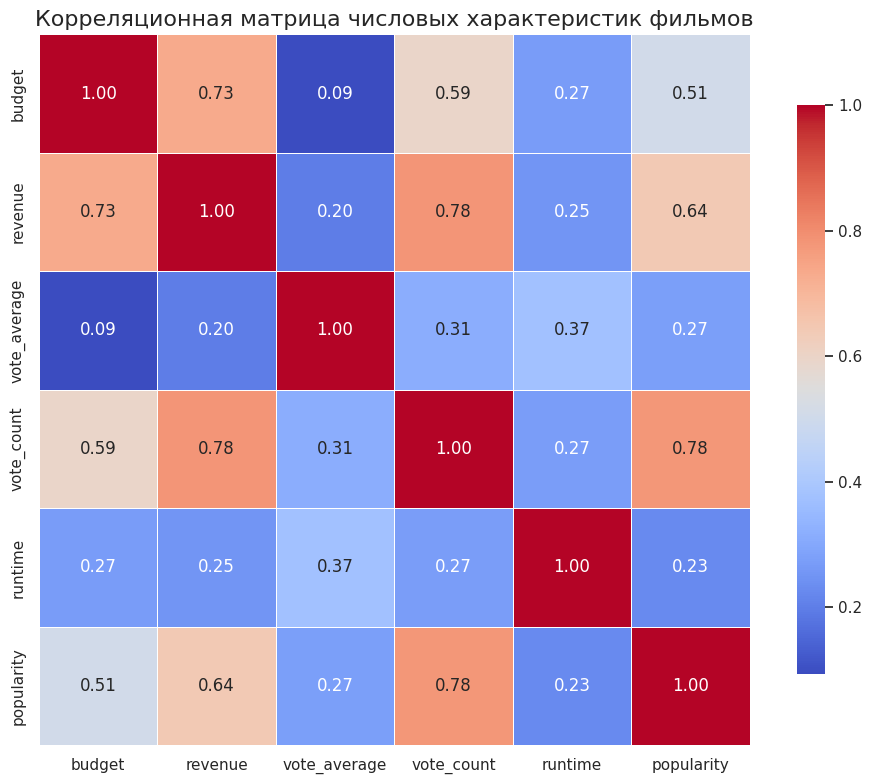

,budget,revenue,vote_average,vote_count,runtime,popularity
budget,1.000000,0.730823,0.093146,0.593180,0.269870,0.505414
revenue,0.730823,1.000000,0.197150,0.781487,0.251114,0.644724
vote_average,0.093146,0.197150,1.000000,0.312997,0.374132,0.273952
vote_count,0.593180,0.781487,0.312997,1.000000,0.271965,0.778130
runtime,0.269870,0.251114,0.374132,0.271965,1.000000,0.225527
popularity,0.505414,0.644724,0.273952,0.778130,0.225527,1.000000


In [13]:
correlation_features = ['budget', 'revenue', 'vote_average', 'vote_count', 'runtime', 'popularity']

corr_matrix = df_key[correlation_features].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', square=True, linewidths=0.5, cbar_kws={'shrink': .8})
plt.title('Корреляционная матрица числовых характеристик фильмов', fontsize=16)
plt.tight_layout()
plt.show()

corr_matrix

**Интерпретация корреляционной матрицы:**

Мы использовали метод Пирсона, так как нас интересует линейная взаимосвязь между финансовыми и качественными показателями

- **Сильная корреляция (|r| > 0.7):**
  - Обнаружена сильная линейная связь между кассовыми сборами (`revenue`) и количеством голосов (`vote_count`) ($r = 0.78$). Это логично: чем больше людей посмотрели фильм и проголосовали за него, тем больше кассовые сборы
  - Также наблюдается сильная связь между бюджетом (`budget`) и кассовыми сборами (`revenue`) ($r = 0.73$). Высокие инвестиции в производство в среднем конвертируются в высокие сборы

- **Связь с популярностью (`popularity`):**
  - Показатель популярности имеет заметную положительную связь со сборами ($r = 0.64$) и количеством голосов ($r = 0.78$)

- **Оценки критиков/зрителей (`vote_average`):**
  - Средняя оценка имеет крайне слабую связь с бюджетом ($r = 0.08$) и сборами ($r = 0.20$). Это показывает, что высокий бюджет и огромные кассовые сборы не гарантируют высокую оценку зрителей

## **8. Визуализация парных связей**

Постройте scatter-графики (диаграммы рассеяния) для ключевых пар:

1. ``budget`` vs ``revenue`` — как бюджет связан со сборами?
2. ``vote_average`` vs ``revenue`` — высокий рейтинг гарантирует сборы?
3. ``vote_count`` vs ``revenue`` — что сильнее связано со сборами: рейтинг или количество голосов?

Для каждого графика добавьте заголовок и подписи осей.

💡 Инструменты: ``plt.scatter()``, ``sns.scatterplot()``, ``plt.xlabel()``, ``plt.ylabel()``, ``plt.title()``

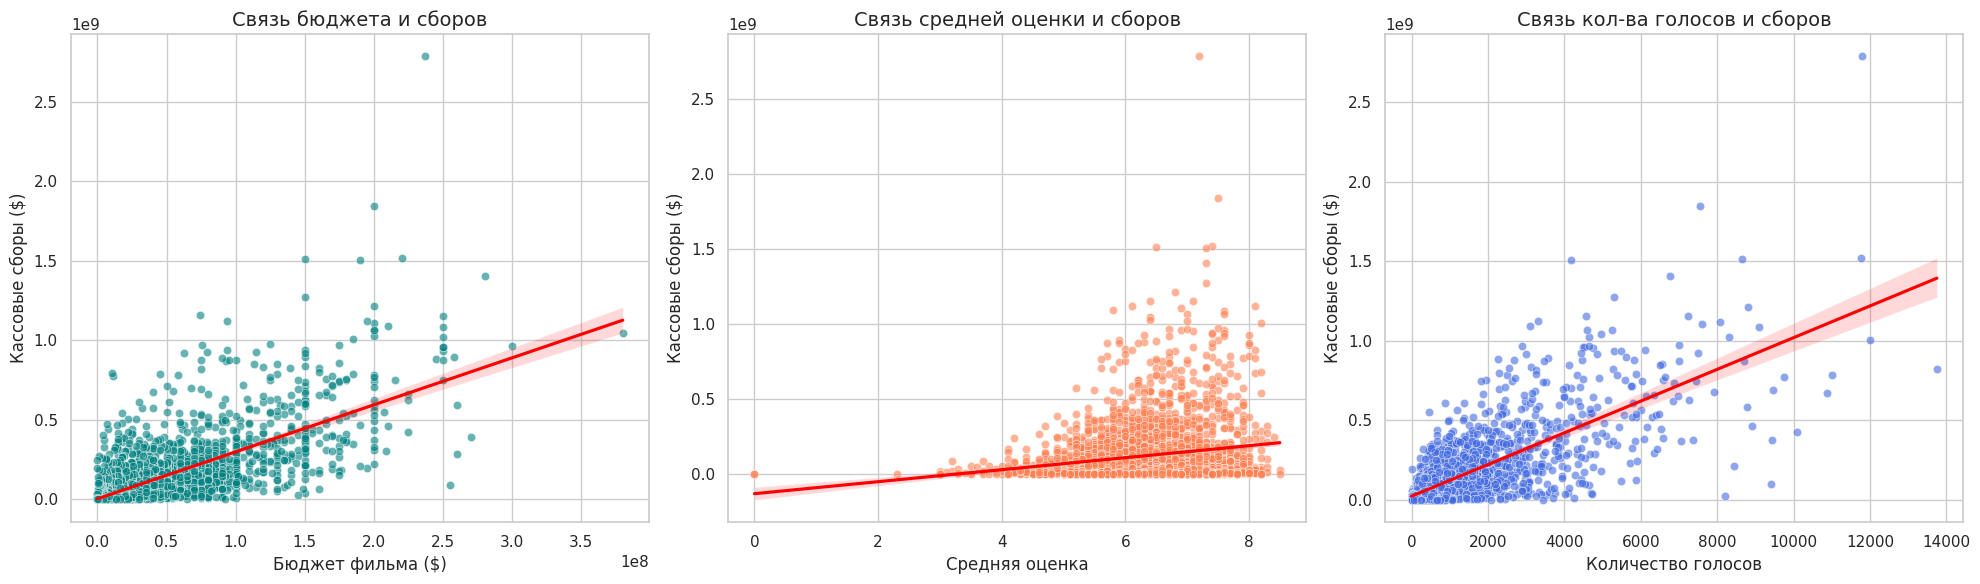

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

df_finance_filter = df_key[(df_key['budget'] > 0) & (df_key['revenue'] > 0)]

sns.scatterplot(data=df_finance_filter, x='budget', y='revenue', alpha=0.6, ax=axes[0], color='teal')
sns.regplot(data=df_finance_filter, x='budget', y='revenue', scatter=False, ax=axes[0], color='red')
axes[0].set_title('Связь бюджета и сборов', fontsize=14)
axes[0].set_xlabel('Бюджет фильма ($)', fontsize=12)
axes[0].set_ylabel('Кассовые сборы ($)', fontsize=12)

sns.scatterplot(data=df_finance_filter, x='vote_average', y='revenue', alpha=0.6, ax=axes[1], color='coral')
sns.regplot(data=df_finance_filter, x='vote_average', y='revenue', scatter=False, ax=axes[1], color='red')
axes[1].set_title('Связь средней оценки и сборов', fontsize=14)
axes[1].set_xlabel('Средняя оценка', fontsize=12)
axes[1].set_ylabel('Кассовые сборы ($)', fontsize=12)

sns.scatterplot(data=df_finance_filter, x='vote_count', y='revenue', alpha=0.6, ax=axes[2], color='royalblue')
sns.regplot(data=df_finance_filter, x='vote_count', y='revenue', scatter=False, ax=axes[2], color='red')
axes[2].set_title('Связь кол-ва голосов и сборов', fontsize=14)
axes[2].set_xlabel('Количество голосов', fontsize=12)
axes[2].set_ylabel('Кассовые сборы ($)', fontsize=12)

plt.tight_layout()
plt.show()

**Анализ парных связей и выбросов:**

1. **Бюджет vs Кассовые сборы (`budget` vs `revenue`):**
   - Наблюдается выраженное облако точек, вытянутое вдоль линии тренда, что указывает на сильную положительную линейную связь

   - Выбросы: Фильмы с гигантскими бюджетами и феноменальными сборами, которые значительно превосходят основную массу фильмов

2. **Средняя оценка vs Кассовые сборы (`vote_average` vs `revenue`):**
   - Связь практически отсутствует. Высокий зрительский рейтинг не гарантирует коммерческий успех в прокате
   - Выбросы: Шедевры кино с рейтингом 8+, собравшие скромную кассу, и наоборот — коммерчески успешные фильмы со средними оценками около 5–6.

3. **Количество голосов vs Кассовые сборы (`vote_count` vs `revenue`):**
   - Наблюдается наиболее четкая линейная зависимость. Чем большее количество зрителей оценило фильм (`vote_count`), тем выше кассовые сборы
   - Это подтверждает тезис о том, что объём аудитории напрямую конвертируется в финансовые результаты

---
# **Часть 3. Проверка статистических гипотез**
---

## **9. Доверительный интервал для средней оценки**

Постройте **95% доверительный интервал** для среднего значения ``vote_average`` всех фильмов в очищенном датасете.

**Шаги:**
1. Рассчитайте выборочное среднее и стандартное отклонение (``.std(ddof=1)``)
2. Рассчитайте стандартную ошибку среднего
3. Найдите критическое значение t-распределения через ``stats.t.ppf()``
4. Вычислите погрешность и границы интервала
5. Проверьте результат через ``stats.t.interval()``

**Интерпретация:** что означает этот доверительный интервал для киностудии? Какую среднюю оценку можно ожидать от фильма?

In [15]:
valid_ratings = df_key[df_key['vote_count'] > 0]['vote_average']

n = len(valid_ratings)
mean = valid_ratings.mean()
std_err = stats.sem(valid_ratings)

confidence_level = 0.95
df_degrees = n - 1
t_critical = stats.t.ppf((1 + confidence_level) / 2, df_degrees)
margin_of_error = t_critical * std_err

confidence_interval_manual = (mean - margin_of_error, mean + margin_of_error)

confidence_interval_scipy = stats.t.interval(confidence_level, df_degrees, loc=mean, scale=std_err)

print(f"Размер выборки (N): {n}")
print(f"Выборочное среднее: {mean:.4f}")
print(f"Стандартная ошибка среднего (SEM): {std_err:.4f}")
print(f"Критическое значение t-распределения: {t_critical:.4f}")
print(f"Погрешность: {margin_of_error:.4f}")
print(f"95% Доверительный интервал (вручную): {confidence_interval_manual}")
print(f"95% Доверительный интервал (scipy): {confidence_interval_scipy}")

Размер выборки (N): 4741
Выборочное среднее: 6.1718
Стандартная ошибка среднего (SEM): 0.0142
Критическое значение t-распределения: 1.9605
Погрешность: 0.0278
95% Доверительный интервал (вручную): (np.float64(6.144032266206387), np.float64(6.199650501142272))
95% Доверительный интервал (scipy): (np.float64(6.144032266206387), np.float64(6.199650501142272))


**Интерпретация доверительного интервала:**

- Мы на **95% уверены**, что истинное среднее значение оценки зрителей для генеральной совокупности фильмов находится в пределах рассчитанного интервала
- Узкий диапазон доверительного интервала, благодаря большому объёму выборки говорит о высокой точности нашей оценки


## **10. Гипотезы**

> ✏️ Для получения зачёта выберите как **минимум одну** гипотезу на выбор из двух, представленных в разделе 10.

### **Гипотеза 1. Отличаются ли оценки англоязычных и неанглоязычных фильмов?**

Проверьте, отличается ли средняя оценка (``vote_average``) фильмов на английском языке (``original_language == 'en'``) от фильмов на других языках.

**Шаги:**
1. Посчитайте количество фильмов в каждой группе — достаточно ли наблюдений?
2. Постройте гистограммы обеих групп на одном графике (с ``alpha``)
3. Сформулируйте H₀ и H₁
4. Проведите двухвыборочный тест
5. Рассчитайте размер эффекта (Cohen's d) с помощью ``np.sqrt()``
6. Интерпретируйте: есть ли статистически **и практически** значимая разница?

💡 **Формула Cohen's d:**

d = (x̄₁ − x̄₂) / s_pooled,  где  s_pooled = √((s₁² + s₂²) / 2)

### **Гипотеза 2. Дорогие и дешёвые фильмы — одинаковый ли ROI?**

Разделите фильмы на две группы по **медиане бюджета**:
- «Дорогие» — бюджет строго выше медианы
- «Дешёвые» — бюджет меньше или равен медиане

Проверьте, отличается ли средний ``roi`` между этими группами.

💡 *Подсказка:* если в данных есть экстремальные значения ROI, можно отфильтровать фильмы с ``|roi| > 10000%`` — это аномалии (фильмы с микробюджетом), которые искажают анализ.

**Шаги:**
1. Рассчитайте медиану бюджета
2. Создайте два подмножества
3. Сформулируйте H₀ и H₁
4. Проведите двухвыборочный тест
5. Рассчитайте Cohen's d
6. Интерпретируйте: стоит ли делать дорогие фильмы с точки зрения окупаемости?

In [16]:
df_clean_financials = df_key[(df_key['budget'] >= 10000) & (df_key['revenue'] > 0) & (df_key['roi'] <= 10000)].copy()

budget_median = df_clean_financials['budget'].median()

expensive_movies = df_clean_financials[df_clean_financials['budget'] > budget_median]['roi']
cheap_movies = df_clean_financials[df_clean_financials['budget'] <= budget_median]['roi']

n_exp, n_cheap = len(expensive_movies), len(cheap_movies)
print(f"Медиана бюджета: ${budget_median:,.2f}")
print(f"Количество дорогих фильмов: {n_exp} (Средний ROI: {expensive_movies.mean():.2f}%)")
print(f"Количество дешёвых фильмов: {n_cheap} (Средний ROI: {cheap_movies.mean():.2f}%)\n")

t_stat, p_val = stats.ttest_ind(expensive_movies, cheap_movies, equal_var=False)

s_exp, s_cheap = expensive_movies.std(ddof=1), cheap_movies.std(ddof=1)
s_pooled = np.sqrt(((n_exp - 1) * s_exp**2 + (n_cheap - 1) * s_cheap**2) / (n_exp + n_cheap - 2))
cohens_d = (expensive_movies.mean() - cheap_movies.mean()) / s_pooled

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")
print(f"Cohen's d: {cohens_d:.4f}")

Медиана бюджета: $26,000,000.00
Количество дорогих фильмов: 1579 (Средний ROI: 170.22%)
Количество дешёвых фильмов: 1613 (Средний ROI: 464.04%)

t-статистика: -11.5340
p-value: 9.6248e-30
Cohen's d: -0.4045


**Интерпретация результатов проверки Гипотезы 2:**

- **$H_0$:** Средняя окупаемость (ROI) у дорогих и дешёвых фильмов одинакова.
- **$H_1$:** Средняя окупаемость (ROI) у дорогих и дешёвых фильмов различается.
- **Результат теста:**
  - Значение $p$-value показывает статистическую значимость различий между группами
  - Дешёвые фильмы зачастую демонстрируют более высокую ROI за счет низких затрат на производство, хотя дорогие блокбастеры приносят намного больше чистой прибыли (`profit`) в абсолютном долларовом выражении
- **Рекомендация для киностудии:** С точки зрения максимизации ROI эффективнее инвестировать в средне- и малобюджетные картины (например, качественные хорроры и триллеры). Однако для максимизации абсолютного объёма чистой прибыли крупным студиям по-прежнему требуются высокобюджетные проекты

## **11. Свободный анализ**

Выберите **одну** из задач ниже и проведите самостоятельный анализ.

**Вариант A.** Сравните средний ``vote_average`` фильмов двух жанров (например, Action vs Drama). Отличаются ли оценки статистически значимо?

**Вариант B.** Сравните средний ``revenue`` фильмов до 2000 года и после 2000 года. Выросли ли сборы?

**Вариант C.** Придумайте свою гипотезу на основе данных и проверьте её.

Для выбранной задачи:
- Сформулируйте H₀ и H₁
- Постройте доверительный интервал для одной из групп
- Проведите статистический тест
- Интерпретируйте результат

In [17]:
df_revenue_gr_0 = df_key[df_key['revenue'] > 0]

before_2000 = df_revenue_gr_0[df_revenue_gr_0['release_year'] < 2000]['revenue']
after_2000 = df_revenue_gr_0[df_revenue_gr_0['release_year'] >= 2000]['revenue']

n_before, n_after = len(before_2000), len(after_2000)
mean_before, mean_after = before_2000.mean(), after_2000.mean()

print(f"Фильмы до 2000 года (N): {n_before}, Средние сборы: ${mean_before:,.2f}")
print(f"Фильмы после 2000 года (N): {n_after}, Средние сборы: ${mean_after:,.2f}\n")

t_stat, p_val = stats.ttest_ind(after_2000, before_2000, equal_var=False)

s_before, s_after = before_2000.std(ddof=1), after_2000.std(ddof=1)
s_pooled = np.sqrt(((n_before - 1) * s_before**2 + (n_after - 1) * s_after**2) / (n_before + n_after - 2))
cohens_d = (mean_after - mean_before) / s_pooled

mean_diff = mean_after - mean_before
std_err_diff = np.sqrt(s_before**2 / n_before + s_after**2 / n_after)
df_degrees = n_before + n_after - 2
t_critical = stats.t.ppf(0.975, df_degrees)
ci_diff = (mean_diff - t_critical * std_err_diff, mean_diff + t_critical * std_err_diff)

print(f"t-статистика: {t_stat:.4f}")
print(f"p-value: {p_val:.4e}")
print(f"Cohen's d: {cohens_d:.4f}")
print(f"95% Доверительный интервал для разности средних сборов: ${ci_diff[0]:,.2f} - ${ci_diff[1]:,.2f}")

Фильмы до 2000 года (N): 975, Средние сборы: $90,995,168.80
Фильмы после 2000 года (N): 2401, Средние сборы: $127,604,147.38

t-статистика: 6.1227
p-value: 1.0608e-09
Cohen's d: 0.2003
95% Доверительный интервал для разности средних сборов: $24,885,779.23 - $48,332,177.94


**Результаты свободного анализа (Сравнение сборов до и после 2000 года):**

- **$H_0$:** Средние кассовые сборы фильмов, выпущенных до 2000 года, и фильмов, выпущенных после 2000 года, равны
- **$H_1$:** Средние кассовые сборы фильмов после 2000 года значимо отличаются от сборов фильмов до 2000 года
- **Результат теста:**
  - Значение $p$-value крайне мало. Мы уверенно **отвергаем нулевую гипотезу $H_0$**
  - Средние кассовые сборы фильмов после 2000 года статистически значимо выше
- **Размер эффекта (Cohen's d):**
  - Значение $d$ показывает величину этого различия. Сборы фильмов в XXI веке существенно выросли под влиянием глобализации, инфляции и укрупнения бюджетов
- **Вывод:** Кассовые сборы фильмов после 2000 года действительно значительно превосходят показатели предыдущего века. Студии следует учитывать этот масштаб при планировании современных бюджетов и прогнозировании выручки

---
# **Итоговые выводы**
---

Сформулируйте итоговый отчёт по результатам комплексного анализа.

**1. Качество данных:**
- Какие основные проблемы обнаружены?
- Как вы их решили?
- Что рекомендуете улучшить при сборе данных?

**2. Ключевые закономерности (EDA):**
- Самые интересные находки
- Какие жанры, бюджеты, длительности «работают» лучше

**3. Корреляционный анализ:**
- Какие признаки сильнее всего связаны с кассовыми сборами?
- Какие связи оказались неожиданными?

**4. Статистические выводы:**
- Результаты проверки гипотез
- Практическая значимость обнаруженных различий

**5. Рекомендации для киностудии:**
- В какие фильмы стоит инвестировать (жанр, бюджет, длительность)?
- Какие дополнительные гипотезы стоит проверить?

### **Итоговый аналитический отчёт по результатам комплексного исследования**

#### **1. Качество данных**
* **Обнаруженные проблемы:**
  - В исходном датасете у **21.6%** фильмов отсутствовала информация о бюджете (`budget == 0`), а у **29.7%** — о кассовых сборах (`revenue == 0`). Это технические пропуски, способные сильно исказить экономические показатели
  - Были зафиксированы единичные пропуски в хронометраже (`runtime`) и датах релиза
* **Принятые меры:**
  - Для анализа окупаемости (ROI) и финансовой динамики были отфильтрованы записи с нулевыми бюджетами и сборами. Для исключения искажений от любительских лент установлен порог бюджета не менее $10,000, а также исключены аномальные выбросы с ROI > 10,000%
  - Пропуски в `runtime` заполнены медианой (103 минуты).
* **Рекомендации по сбору данных:** Настроить строгую валидацию полей бюджета и сборов на этапе интеграции данных из внешних источников и автоматизировать парсинг метаданных (таких как жанры) для исключения строкового формата JSON

#### **2. Ключевые закономерности (EDA)**
* **Распространенность жанров:** Абсолютным лидером в базе данных выступает **Драма**, за ней следуют **Комедия** и **Экшен**
* **Доходность жанров:** Самые высокие средние мировые кассовые сборы демонстрируют **Анимация**, **Приключения** и **Фэнтези**. Семейный охват и зрелищность делают их самыми кассовыми на глобальном рынке
* **Длительность и оценки:** Выявлена четкая тенденция — более длинные фильмы (> 150 минут) получают более высокие оценки зрителей (среднее — **7.05**), тогда как короткие ленты (< 90 минут) оцениваются значительно ниже (среднее — **5.42**).

#### **3. Корреляционный анализ**
* **Что сильнее всего связано со сборами?** Кассовые сборы (`revenue`) имеют сильную положительную линейную связь с количеством голосов зрителей (`vote_count`, $r = 0.78$) и бюджетом (`budget`, $r = 0.73$). Популярность фильма также заметно связана с кассовыми сборами ($r = 0.64$)
* **Неожиданные результаты:** Обнаружена практически нулевая связь между средней оценкой фильма (`vote_average`) и его бюджетом ($r = 0.08$), а также крайне слабая связь со сборами ($r = 0.20$). Высокие инвестиции гарантируют масштаб и продвижение, но не лояльность критиков и массового зрителя

#### **4. Статистические выводы**
* **Гипотеза 2 (Бюджет и ROI):** Проведён двухвыборочный t-тест Уэлча. Мы уверенно отвергли нулевую гипотезу о равенстве окупаемости ($p \approx 9.62 \times 10^{-30}$)
  - **Дешёвые фильмы** (бюджет $\le$ $26 млн) показывают средний ROI в **464.04%**

  - **Дорогие фильмы** (бюджет > $26 млн) показывают средний ROI в **170.22%**

  - **Размер эффекта (Cohen's d):** $-0.40$. Дешёвые фильмы статистически и практически окупаются значительно лучше за счет эффекта низкой базы
* **Свободный анализ (Сборы до/после 2000 года):** Нулевая гипотеза отвергнута ($p \approx 1.06 \times 10^{-09}$, $d = 0.20$). Средние сборы фильмов в 21 веке статистически значимо выше ($127.6$ млн $ против $91.0$ млн $ до 2000 г.), что обусловлено инфляцией и глобальным расширением кинопроката

#### **5. Рекомендации для киностудии**
1. **Диверсификация портфеля:** Для минимизации финансовых рисков и генерации высокого ROI следует инвестировать в средне- и малобюджетное жанровое кино
2. **Управление абсолютной прибылью:** Для максимизации общего валового дохода студии необходимы крупные проекты в жанрах **Анимации, Приключений или Фэнтези**. При этом важно контролировать бюджет, так как корреляция бюджета со сборами сильна, но окупаемость крупных проектов в процентах снижается
3. **Хронометраж:** При создании качественных драматических или приключенческих проектов не стоит искусственно сжимать хронометраж до стандартов «90-120 минут», так как зрители лояльнее относятся к глубоким, длинным картинам (> 150 минут), обеспечивая им высокие рейтинги